In [1]:
import numpy as np
import pandas as pd

from scipy.stats import ecdf

from lifelines import KaplanMeierFitter
from lifelines import CoxPHFitter

import matplotlib.pyplot as plt

import testis_model as tm

In [2]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 12,              # base font size
    'xtick.labelsize': 7,        # x-axis tick label size
    'ytick.labelsize': 7,        # y-axis tick label size
    'axes.labelsize': 12,         # axis label size
    'axes.titlesize': 12,         # title size
    'legend.fontsize': 12,        # legend font size
    'figure.titlesize': 12        # figure title size
})

In [3]:
df = pd.read_csv('../model_simulations/all_clone_results.csv')

bad_fish = [6,9,11,21,23,41,43,34]
df = df.query('scenario != "real" or ~fish.isin(@bad_fish)').copy()

In [4]:
df.head()

,scenario,fish,clone,init_time,init_freq,last_time,max_time,max_freq,size,avg_freq_change,r_opt,if_opt,l_max,lower,upper,if_null,l_null
0,n500_r15_y6,0,0,5.0,0.555256,25.0,26.0,0.0,0.285664,0.025606,26.547272,0.551790,-212.780255,11.670349,70.666996,0.288180,-2317.466955
1,n500_r15_y6,0,1,5.0,0.311770,18.0,26.0,0.0,0.144305,0.023913,24.128502,0.316866,-157.553822,10.354475,67.457306,0.144305,-3094.812299
2,n500_r15_y6,0,2,5.0,0.132974,26.0,26.0,1.0,0.570031,-0.041287,23.602596,0.144224,-211.285386,10.235373,63.934861,0.569150,-5935.367621
3,n500_r15_y6,1,0,5.0,0.365678,14.0,26.0,0.0,0.122192,0.031347,25.003799,0.369282,-120.251278,8.721297,104.718456,0.122192,-2597.410266
4,n500_r15_y6,1,1,5.0,0.331536,24.0,26.0,0.0,0.182390,0.014896,22.722833,0.336038,-192.071656,9.610288,63.928778,0.183544,-1403.052886


In [5]:
# sample_map = tm.data_processing.sample_map_int

# df['max_time'] = df['max_time'].map(sample_map)
# df['last_time'] = df['last_time'].map(sample_map)#.fillna(df['max_time'])

# truncate_time = 26
# df['last_time'] = np.minimum(truncate_time, df['last_time'])
# df['max_time'] = np.minimum(truncate_time, df['max_time'])

df['died_early'] = df['last_time'] != df['max_time']

# df['died_early'] = ~df['last_time'].isna()
# df['last_time'] = df['last_time'].fillna(df['max_time'])
df.head()

,scenario,fish,clone,init_time,init_freq,last_time,max_time,max_freq,size,avg_freq_change,r_opt,if_opt,l_max,lower,upper,if_null,l_null,died_early
0,n500_r15_y6,0,0,5.0,0.555256,25.0,26.0,0.0,0.285664,0.025606,26.547272,0.551790,-212.780255,11.670349,70.666996,0.288180,-2317.466955,True
1,n500_r15_y6,0,1,5.0,0.311770,18.0,26.0,0.0,0.144305,0.023913,24.128502,0.316866,-157.553822,10.354475,67.457306,0.144305,-3094.812299,True
2,n500_r15_y6,0,2,5.0,0.132974,26.0,26.0,1.0,0.570031,-0.041287,23.602596,0.144224,-211.285386,10.235373,63.934861,0.569150,-5935.367621,False
3,n500_r15_y6,1,0,5.0,0.365678,14.0,26.0,0.0,0.122192,0.031347,25.003799,0.369282,-120.251278,8.721297,104.718456,0.122192,-2597.410266,True
4,n500_r15_y6,1,1,5.0,0.331536,24.0,26.0,0.0,0.182390,0.014896,22.722833,0.336038,-192.071656,9.610288,63.928778,0.183544,-1403.052886,True


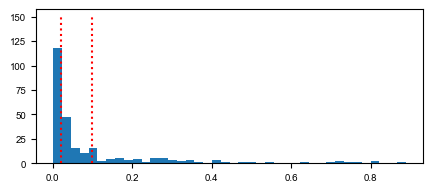

In [6]:
small_cutoff = 0.02
large_cutoff = 0.10

fig, ax = plt.subplots(figsize = (5, 2))

real_df = df.query('scenario == "real"')
ax.hist(real_df['init_freq'], bins=40)
ax.vlines(x=small_cutoff, ymin=0, ymax=150, colors='r', linestyles='dotted', zorder=1)
ax.vlines(x=large_cutoff, ymin=0, ymax=150, colors='r', linestyles='dotted', zorder=1)

In [7]:
print(f"""\
{100*(real_df['init_freq'] < small_cutoff).mean():.1f}% of clones have a size below {small_cutoff:.2f}, \
{100*((real_df['init_freq'] > small_cutoff) & (real_df['init_freq'] < large_cutoff)).mean():.1f}% \
have a size between {small_cutoff:.2f} and {large_cutoff:.2f}, and \
{100*(real_df['init_freq'] > large_cutoff).mean():.1f}% of clones have a size above {large_cutoff:.2f}.\
""")

40.1% of clones have a size below 0.02, 35.1% have a size between 0.02 and 0.10, and 24.8% of clones have a size above 0.10.


In [8]:
df.loc[df['init_freq'] < large_cutoff, 'tertile'] = 'medium'
df.loc[df['init_freq'] < small_cutoff, 'tertile'] = 'small'
df.loc[df['init_freq'] > large_cutoff, 'tertile'] = 'large'

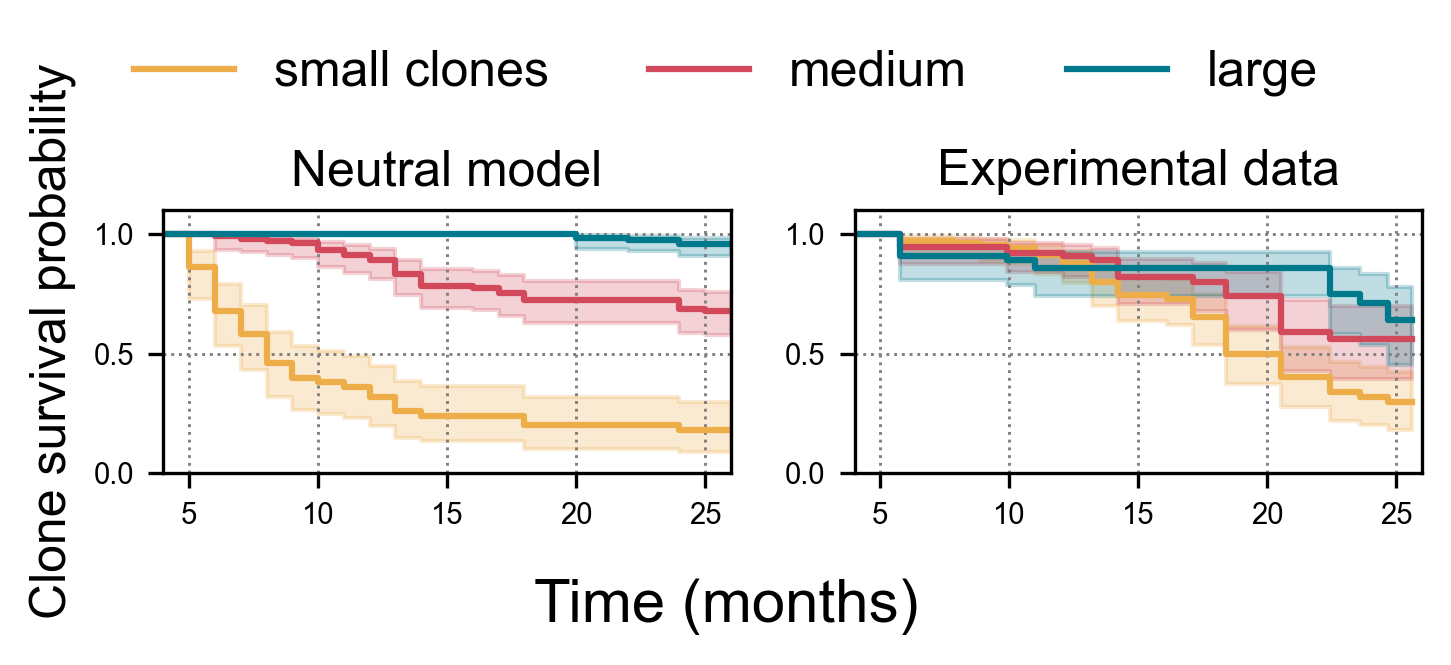

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(5, 2), dpi = 300)

n_experimental_fish = 30
compare_scenario = 'n1000_r2.5_y6'

kmf = dict()
subset = dict()
for i, s in enumerate([compare_scenario, 'real']):
    # Filter the DataFrame
    
    # Instantiate the KaplanMeierFitter
    kmf[s, 'sm'] = KaplanMeierFitter()
    kmf[s, 'md'] = KaplanMeierFitter()
    kmf[s, 'lg'] = KaplanMeierFitter()

    data = df.query('scenario == @s')
    if s == 'real':
        subset[s, 'sm'] = data.query('tertile == "small"')
        subset[s, 'md'] = data.query('tertile == "medium"')
        subset[s, 'lg'] = data.query('tertile == "large"')
    else:
        # subset 'fish <= 30' so that we are comparing similar amounts of
        # experimental & real data.
        subset[s, 'sm'] = data.query('tertile == "small" and fish <= @n_experimental_fish')
        subset[s, 'md'] = data.query('tertile == "medium" and fish <= @n_experimental_fish')
        subset[s, 'lg'] = data.query('tertile == "large" and fish <= @n_experimental_fish')

    sm, md, lg = subset[s, 'sm'], subset[s, 'md'], subset[s, 'lg']
    
    # Fit the model — assuming all events are observed (no censoring)
    kmf[s, 'sm'].fit(durations = sm['last_time'], event_observed = sm['died_early'])
    kmf[s, 'md'].fit(durations = md['last_time'], event_observed = md['died_early'])
    kmf[s, 'lg'].fit(durations = lg['last_time'], event_observed = lg['died_early'])
    
    # Plot the survival curve
    kmf[s, 'sm'].plot_survival_function(ax = ax[i], label='small clones', color = '#edae49')
    kmf[s, 'md'].plot_survival_function(ax = ax[i], label='medium', color = '#d1495b')
    kmf[s, 'lg'].plot_survival_function(ax = ax[i], label='large', color = '#00798c')
    # ax[i].set_title(f'{g}')
    ax[i].set_xlabel('')
    # ax[i].set_ylabel('Survival Probability')
    ax[i].grid(True, linestyle=':', linewidth=0.7, color='gray')
    ax[i].set_xticks([5, 10, 15, 20, 25])
    ax[i].set_xlim([4, 26])
    ax[i].set_ylim([0, 1.1])
    ax[i].set_title('Neutral model' if i == 0 else 'Experimental data')
    ax[i].legend_.remove()
    if i == 0:
        ax[i].set_ylabel('Clone survival probability')

# After plotting all curves
handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.15), ncol=3, frameon=False)
fig.supxlabel("Time (months)", y=0.1)

plt.tight_layout()
# plt.savefig('./images/survivorship-tertile.png', transparent = True, bbox_inches = 'tight')

In [10]:
df[df['scenario'].isin(['real', compare_scenario])].groupby('scenario').agg({'died_early': 'mean'})
# Slightly more of the simulations died early in this comparison.

,died_early
scenario,
n1000_r2.5_y6,0.290076
real,0.316794


In [11]:
from lifelines import CoxPHFitter

# Subset to relevant scenarios
df_sub = df[df['scenario'].isin(['real', 'n1000_r4_y6'])].copy()

# Ensure 'scenario' is treated as a categorical variable
df_sub['scenario'] = df_sub['scenario'].astype('category')

# Fit Cox model with interaction
cph = CoxPHFitter()
cph.fit(df_sub, duration_col='last_time', event_col='died_early', formula='init_freq * scenario')

# Print results
print("Interaction model: init_freq × scenario")
cph.print_summary()

Interaction model: init_freq × scenario


<lifelines.CoxPHFitter: fitted with 1120 total observations, 705 right-censored observations>
             duration col = 'last_time'
                event col = 'died_early'
      baseline estimation = breslow
   number of observations = 1120
number of events observed = 415
   partial log-likelihood = -2545.03
         time fit was run = 2025-11-24 18:26:29 UTC

---
                             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                    
init_freq                  -24.14      0.00      1.51          -27.10          -21.18                0.00                0.00
scenario[T.real]            -1.58      0.21      0.16           -1.89           -1.28                0.15                0.28
init_freq:scenario[T.real]  22.11  4.02e+09      1.80           18.58           25.65            1.17e+08            1.38e+11

                            cmp to      z      p  -log2(p)
covariate                                                 
init_freq                     0.00 -15.99 <0.005    188.80
scenario[T.real]              0.00 -10.14 <0.005     77.80
init_freq:scenario[T.real]    0.00  12.27 <0.005    112.50
---
Concordance = 0.82
Partial AIC = 5096.05
log-likelihood ratio test = 493.20 on 3 df
-log2(p) of ll-ratio test = 351.61

In [24]:
# Cox proportional hazards model with `init_freq` as covariate

# Subset for 'real'
df_real = df[df['scenario'] == 'real']
cph_real = CoxPHFitter()
cph_real.fit(df_real[['last_time', 'died_early', 'init_freq']], duration_col='last_time', event_col='died_early')
print("Results for scenario: real")
cph_real.print_summary()

Results for scenario: real


<lifelines.CoxPHFitter: fitted with 306 total observations, 218 right-censored observations>
             duration col = 'last_time'
                event col = 'died_early'
      baseline estimation = breslow
   number of observations = 306
number of events observed = 88
   partial log-likelihood = -433.31
         time fit was run = 2025-11-17 17:11:51 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
init_freq -2.34      0.10      0.95           -4.21           -0.47                0.01                0.63

           cmp to     z    p  -log2(p)
covariate                             
init_freq    0.00 -2.45 0.01      6.13
---
Concordance = 0.59
Partial AIC = 868.62
log-likelihood ratio test = 8.37 on 1 df
-log2(p) of ll-ratio test = 8.04